### Environment & Dataset Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plot aesthetics setup
sns.set_theme(style="whitegrid")
%matplotlib inline

# Load real-world dataset directly from seaborn
df_raw = sns.load_dataset('titanic')

print(f"Dataset Shape: {df_raw.shape}")
print("\n--- Initial Five Records ---")
df_raw.head()

Dataset Shape: (891, 15)

--- Initial Five Records ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### Structural Inspection & Missing Value Diagnostics

In [2]:
print("--- Data Types and Non-Null Counts ---")
print(df_raw.info())

print("\n--- Missing Value Audit ---")
missing_df = pd.DataFrame({
    'Missing_Count': df_raw.isnull().sum(),
    'Missing_Percentage': (df_raw.isnull().sum() / len(df_raw) * 100).round(2)
})
print(missing_df[missing_df['Missing_Count'] > 0])

print(f"\nDuplicate Records Count: {df_raw.duplicated().sum()}")

--- Data Types and Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB
None

--- Missing Value Audit ---
             Missing

### Data Cleaning & Feature Transformation

In [3]:
df_cleaned = df_raw.copy()

# 1. Deduplication
df_cleaned = df_cleaned.drop_duplicates().reset_index(drop=True)

# 2. Impute Age with median (robust against right-skew)
age_median = df_cleaned['age'].median()
df_cleaned['age'] = df_cleaned['age'].fillna(age_median)

# 3. Impute categorical Embarked with mode
embarked_mode = df_cleaned['embarked'].mode()[0]
df_cleaned['embarked'] = df_cleaned['embarked'].fillna(embarked_mode)
df_cleaned['embark_town'] = df_cleaned['embark_town'].fillna(df_cleaned['embark_town'].mode()[0])

# 4. Drop Deck (due to excessive missingness > 70%)
if 'deck' in df_cleaned.columns:
    df_cleaned = df_cleaned.drop(columns=['deck'])

# 5. Feature Engineering: Family Size & Travel Status
df_cleaned['family_size'] = df_cleaned['sibsp'] + df_cleaned['parch'] + 1
df_cleaned['is_alone'] = (df_cleaned['family_size'] == 1).astype(int)

# 6. Outlier Detection on 'fare' using IQR Method
Q1 = df_cleaned['fare'].quantile(0.25)
Q3 = df_cleaned['fare'].quantile(0.75)
IQR = Q3 - Q1
fare_upper_bound = Q3 + 1.5 * IQR

outlier_fares = df_cleaned[df_cleaned['fare'] > fare_upper_bound]
print(f"Fare Q1: {Q1:.2f} | Fare Q3: {Q3:.2f} | Fare IQR: {IQR:.2f}")
print(f"Fare Outlier Boundary: > {fare_upper_bound:.2f}")
print(f"Number of Fare Outliers: {len(outlier_fares)}")
print(f"Cleaned Dataset Dimensions: {df_cleaned.shape}")

Fare Q1: 8.05 | Fare Q3: 34.11 | Fare IQR: 26.06
Fare Outlier Boundary: > 73.20
Number of Fare Outliers: 102
Cleaned Dataset Dimensions: (784, 16)


### Statistical Aggregation & Demographic Grouping

In [4]:
# Aggregate survival rates by class and gender
demographic_summary = df_cleaned.groupby(['pclass', 'sex']).agg(
    Total_Passengers=('survived', 'count'),
    Total_Survivors=('survived', 'sum'),
    Survival_Rate=('survived', 'mean'),
    Average_Fare=('fare', 'mean'),
    Median_Age=('age', 'median')
).reset_index()

demographic_summary['Survival_Rate'] = (demographic_summary['Survival_Rate'] * 100).round(2)
demographic_summary['Average_Fare'] = demographic_summary['Average_Fare'].round(2)

print("--- Demographic Survival Performance ---")
print(demographic_summary)

--- Demographic Survival Performance ---
   pclass     sex  Total_Passengers  Total_Survivors  Survival_Rate  \
0       1  female                93               90          96.77   
1       1    male               121               45          37.19   
2       2  female                73               67          91.78   
3       2    male                92               17          18.48   
4       3  female               127               60          47.24   
5       3    male               278               44          15.83   

   Average_Fare  Median_Age  
0        106.52        33.0  
1         67.55        36.0  
2         22.19        28.0  
3         21.55        30.0  
4         15.70        25.0  
5         12.72        28.0  


### Visual Analytics & Annotated Correlation Matrix

C:\Users\cmoni\AppData\Local\Temp\ipykernel_10100\3512908180.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(
C:\Users\cmoni\AppData\Local\Temp\ipykernel_10100\3512908180.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(['Perished (0)', 'Survived (1)'])


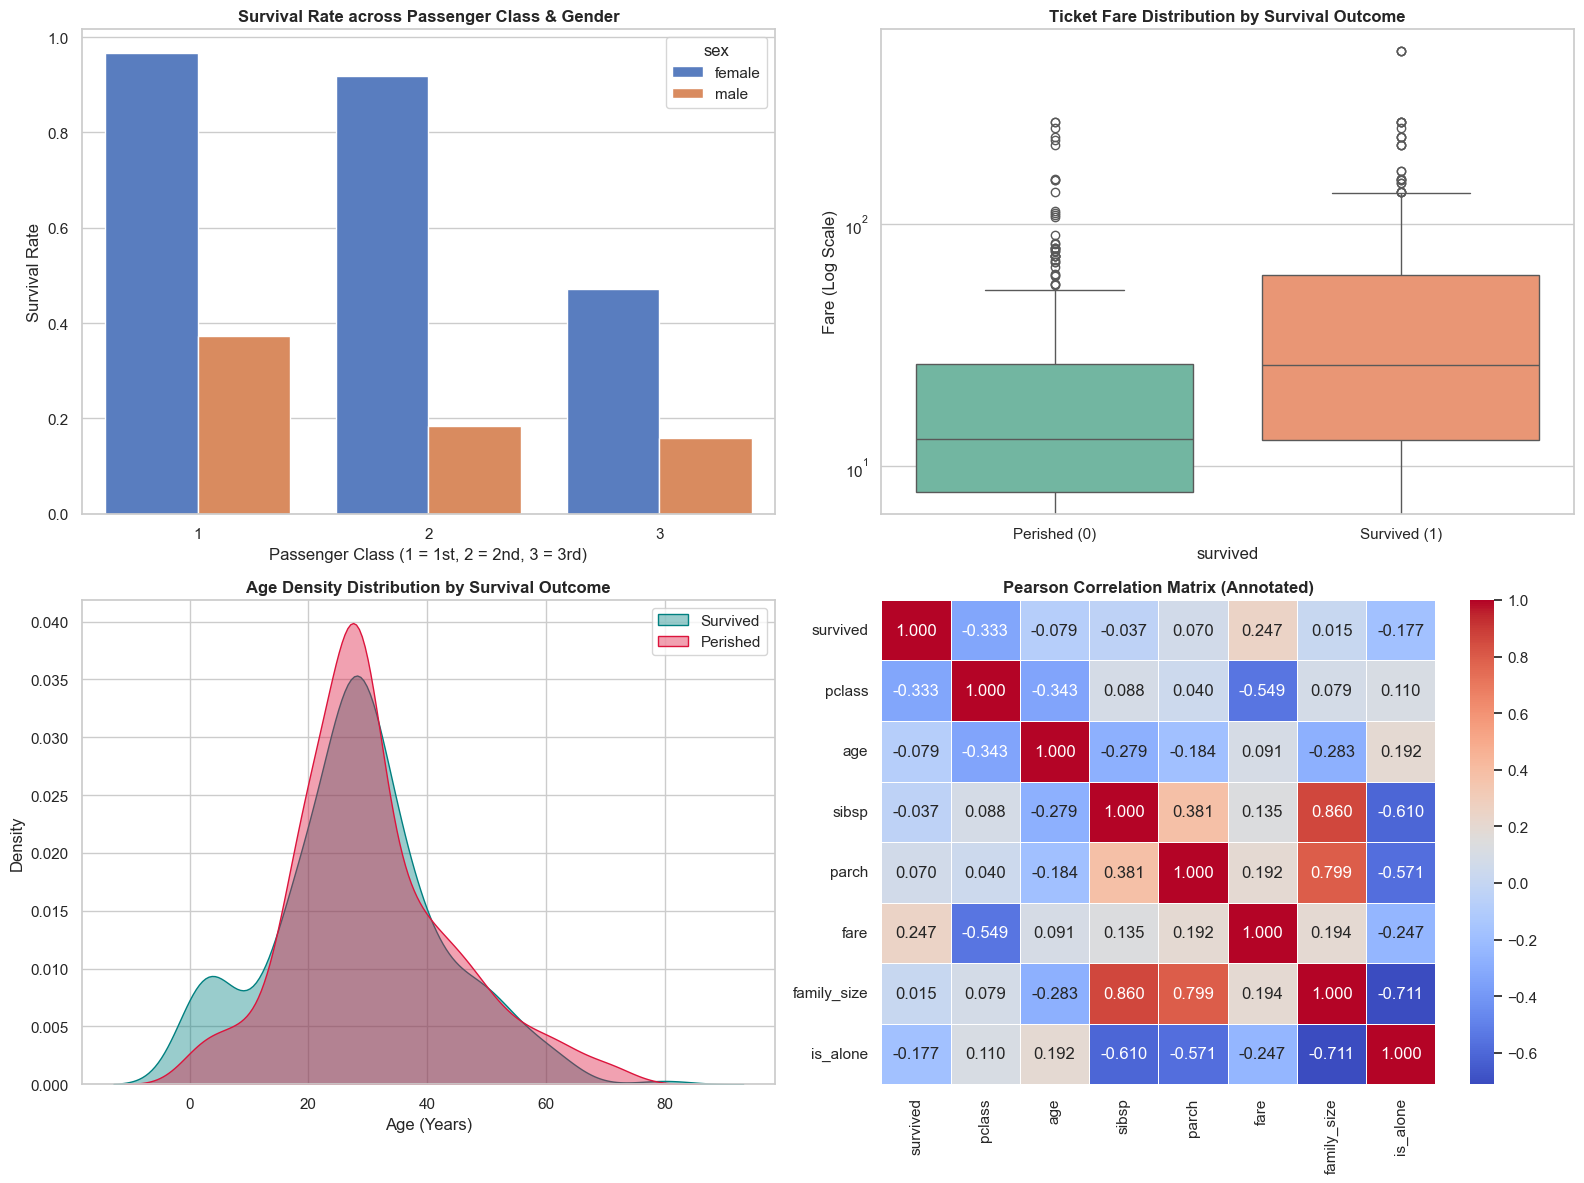


--- Exact Numerical Correlation Matrix ---
             survived  pclass     age   sibsp   parch    fare  family_size  \
survived       1.0000 -0.3327 -0.0792 -0.0366  0.0703  0.2468       0.0150   
pclass        -0.3327  1.0000 -0.3430  0.0880  0.0403 -0.5492       0.0794   
age           -0.0792 -0.3430  1.0000 -0.2794 -0.1838  0.0913      -0.2830   
sibsp         -0.0366  0.0880 -0.2794  1.0000  0.3814  0.1351       0.8603   
parch          0.0703  0.0403 -0.1838  0.3814  1.0000  0.1919       0.7994   
fare           0.2468 -0.5492  0.0913  0.1351  0.1919  1.0000       0.1937   
family_size    0.0150  0.0794 -0.2830  0.8603  0.7994  0.1937       1.0000   
is_alone      -0.1766  0.1095  0.1917 -0.6095 -0.5711 -0.2466      -0.7111   

             is_alone  
survived      -0.1766  
pclass         0.1095  
age            0.1917  
sibsp         -0.6095  
parch         -0.5711  
fare          -0.2466  
family_size   -0.7111  
is_alone       1.0000  


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Survival Rate by Class and Sex
sns.barplot(
    data=df_cleaned, 
    x='pclass', 
    y='survived', 
    hue='sex', 
    ci=None, 
    ax=axes[0, 0], 
    palette='muted'
)
axes[0, 0].set_title('Survival Rate across Passenger Class & Gender', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Survival Rate')
axes[0, 0].set_xlabel('Passenger Class (1 = 1st, 2 = 2nd, 3 = 3rd)')

# 2. Fare Distribution by Survival Status (Log Scale)
sns.boxplot(
    data=df_cleaned, 
    x='survived', 
    y='fare', 
    hue='survived', 
    legend=False, 
    ax=axes[0, 1], 
    palette='Set2'
)
axes[0, 1].set_title('Ticket Fare Distribution by Survival Outcome', fontsize=12, fontweight='bold')
axes[0, 1].set_yscale('log')
axes[0, 1].set_ylabel('Fare (Log Scale)')
axes[0, 1].set_xticklabels(['Perished (0)', 'Survived (1)'])

# 3. Age Distribution by Survival Outcome
sns.kdeplot(
    data=df_cleaned, 
    x='age', 
    hue='survived', 
    common_norm=False, 
    fill=True, 
    alpha=0.4, 
    ax=axes[1, 0], 
    palette=['crimson', 'teal']
)
axes[1, 0].set_title('Age Density Distribution by Survival Outcome', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Age (Years)')
axes[1, 0].legend(['Survived', 'Perished'])

# 4. Correlation Heatmap with Explicit Numerical Values
numeric_cols = ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'family_size', 'is_alone']
corr_matrix = df_cleaned[numeric_cols].corr().round(4)

sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', cbar=True, ax=axes[1, 1], linewidths=0.5)
axes[1, 1].set_title('Pearson Correlation Matrix (Annotated)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n--- Exact Numerical Correlation Matrix ---")
print(corr_matrix)